<a href="https://colab.research.google.com/github/Asinjoji/Casestudy_Unsupervised_Learning/blob/main/Case_study_unsupervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/DSA/Dataset/adult_dataset.csv')
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39.0,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36.0,United-States,<=50K.
48838,64.0,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40.0,United-States,<=50K.
48839,38.0,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50.0,United-States,<=50K.
48840,44.0,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40.0,United-States,<=50K.


In [ ]:
print(df.head())
print(df.shape)
print(df.info())

    age         workclass  fnlwgt  education  education-num  \
0  39.0         State-gov   77516  Bachelors             13   
1  50.0  Self-emp-not-inc   83311  Bachelors             13   
2  38.0           Private  215646    HS-grad              9   
3  53.0           Private  234721       11th              7   
4  28.0           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0            40.0            NaN  <=50K  
1             0             0       

In [ ]:
# Replace ? with NaN
df.replace("?", np.nan, inplace=True)

# Check missing values
print(df.isnull().sum())

age               2442
workclass         5125
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    3260
income               0
dtype: int64


In [ ]:
num_cols = [
    'age', 'fnlwgt', 'education-num',
    'capital-gain', 'capital-loss', 'hours-per-week'
]

cat_cols = [
    'workclass', 'education', 'marital-status',
    'occupation', 'relationship', 'race',
    'sex', 'native-country'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [ ]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Income is excluded from clustering
X = df[num_cols + cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

X_scaled = preprocessor.fit_transform(X)

print(X_scaled.shape)

(48842, 105)


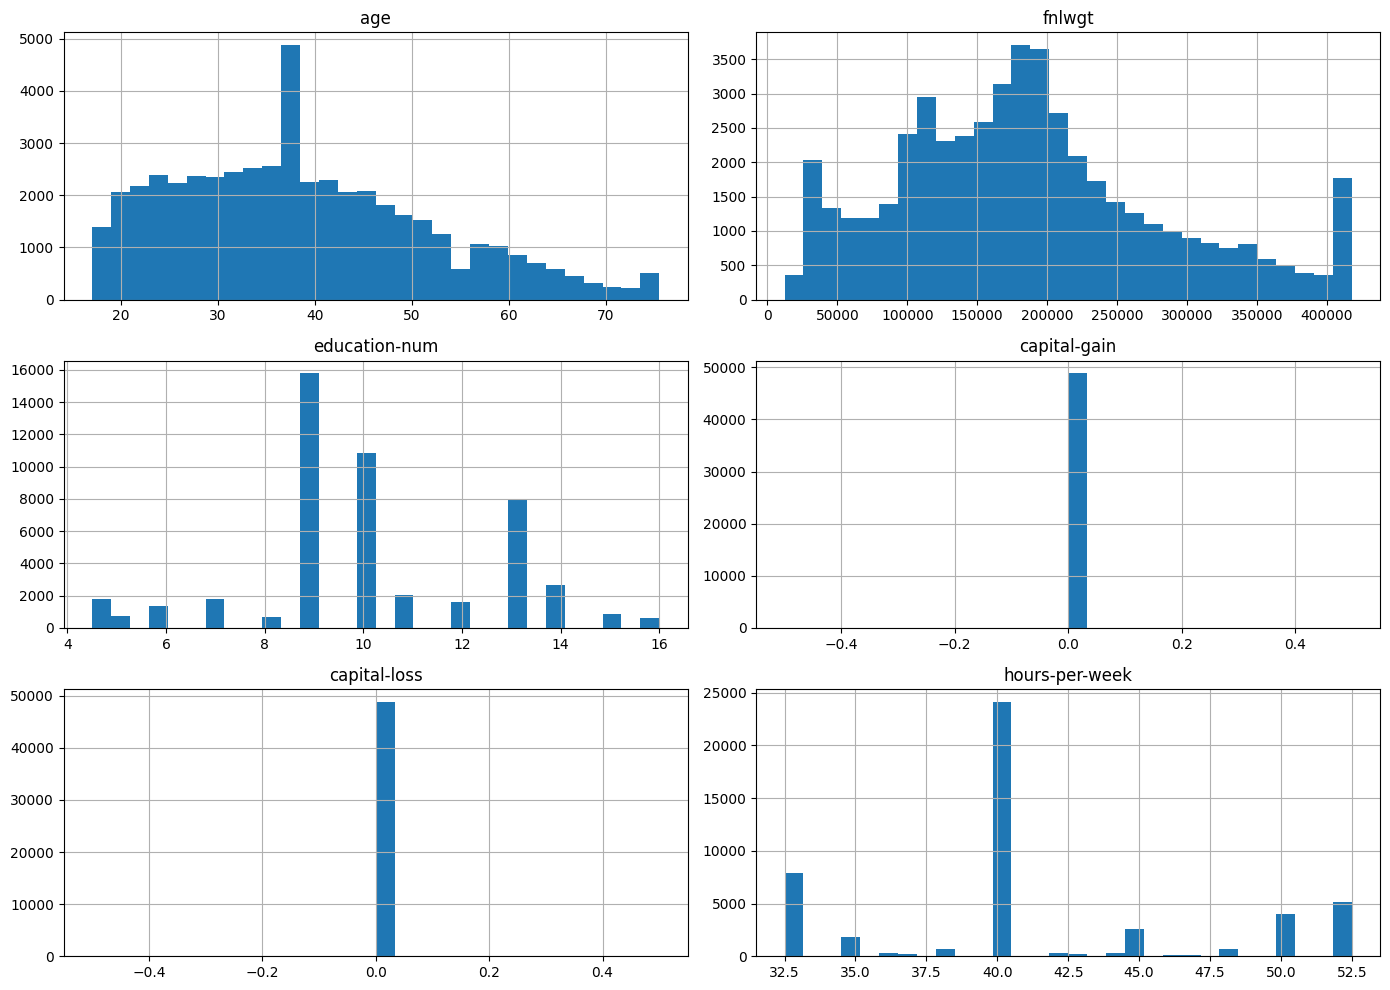

In [ ]:
df[num_cols].hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

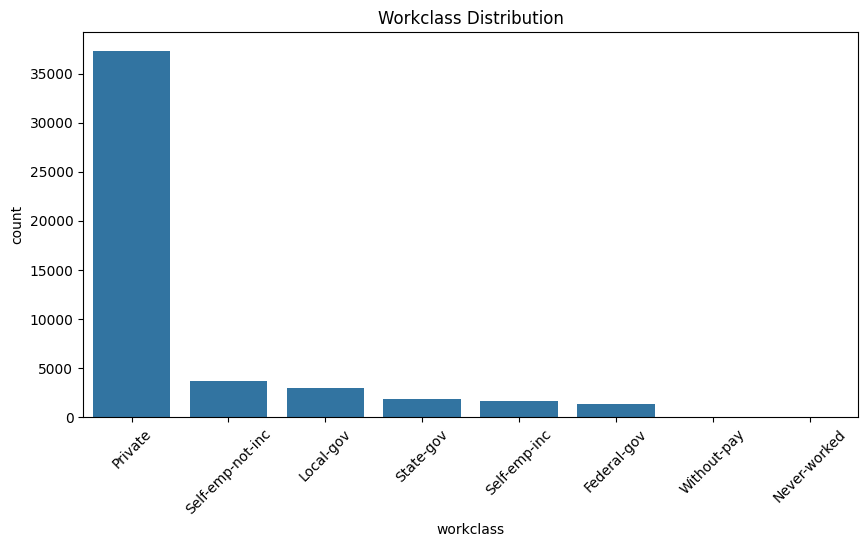

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='workclass',
              order=df['workclass'].value_counts().index)

plt.xticks(rotation=45)
plt.title("Workclass Distribution")
plt.show()

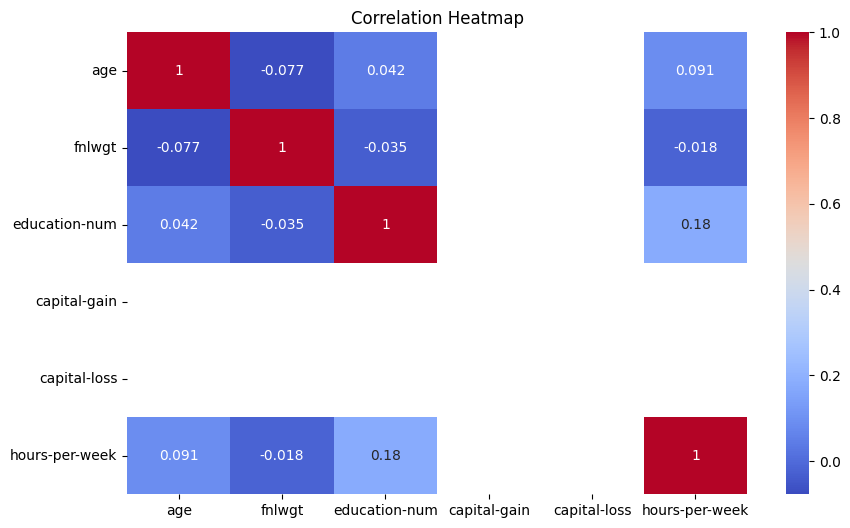

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

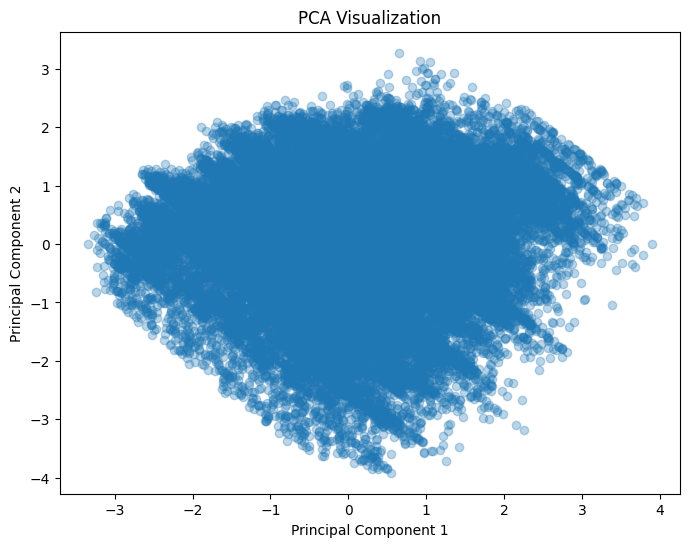

Explained Variance: [0.18122841 0.13300842]


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled.toarray())

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.3)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")
plt.show()

print("Explained Variance:",
      pca.explained_variance_ratio_)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use a reproducible sample
sample_size = min(8000, len(df))

X_sample = X_scaled[:sample_size]

inertia = []
silhouette_scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_sample)

    inertia.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(X_sample, labels)
    )

print("Silhouette Scores:", silhouette_scores)

Silhouette Scores: [np.float64(0.1184530395456996), np.float64(0.1170220344536651), np.float64(0.11303333985014613), np.float64(0.10773122602761225), np.float64(0.10377059908901179)]


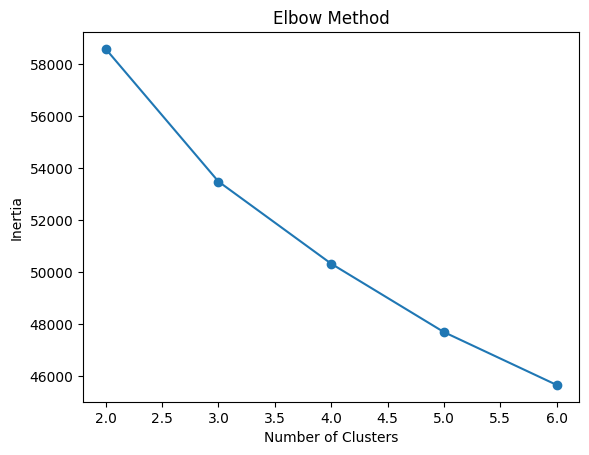

In [ ]:
plt.plot(range(2, 7), inertia, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.title("Elbow Method")
plt.show()

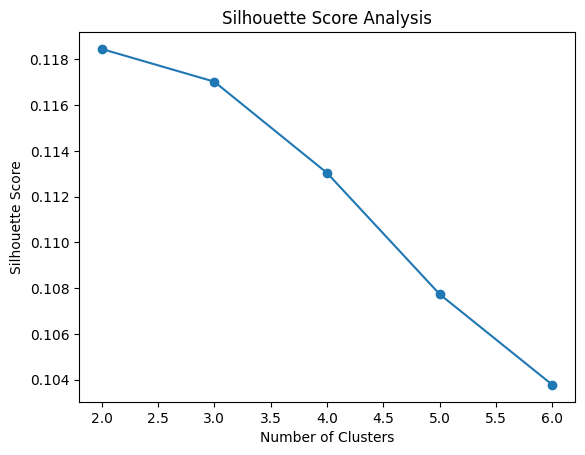

In [ ]:
plt.plot(range(2, 7), silhouette_scores, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score Analysis")
plt.show()

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_sample)

print(kmeans_labels)

[2 2 0 ... 2 0 1]


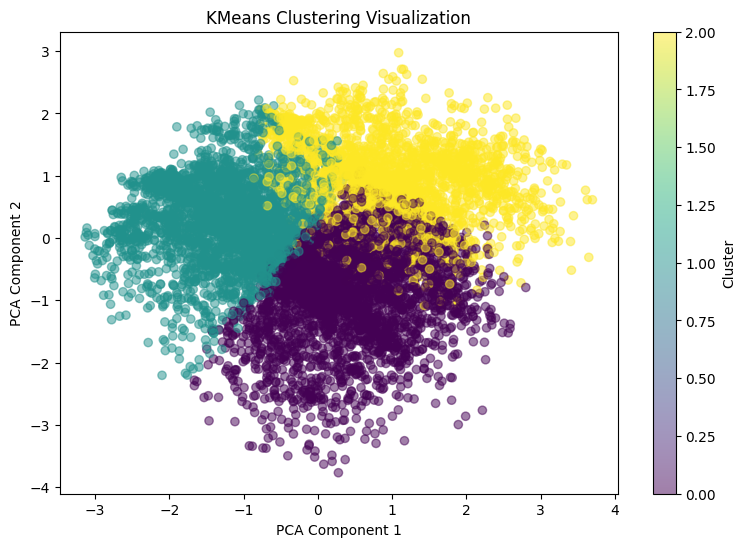

In [ ]:
pca = PCA(n_components=2)

X_pca_sample = pca.fit_transform(X_sample.toarray())

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca_sample[:, 0],
    X_pca_sample[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    alpha=0.5
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title("KMeans Clustering Visualization")
plt.colorbar(label="Cluster")

plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

agglo_size = min(2500, X_sample.shape[0])

X_agglo = X_sample[:agglo_size]

agglo = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

agglo_labels = agglo.fit_predict(
    X_agglo.toarray()
)

print(agglo_labels)

[0 2 1 ... 2 2 0]


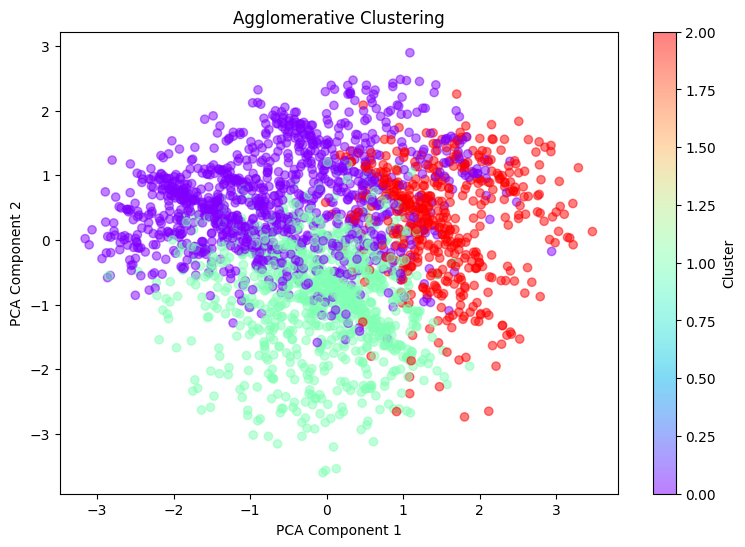

In [ ]:
X_agglo_pca = PCA(n_components=2).fit_transform(
    X_agglo.toarray()
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_agglo_pca[:, 0],
    X_agglo_pca[:, 1],
    c=agglo_labels,
    cmap='rainbow',
    alpha=0.5
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.title("Agglomerative Clustering")

plt.colorbar(label="Cluster")

plt.show()

In [ ]:
cluster_df = df.iloc[:sample_size].copy()

cluster_df['Cluster'] = kmeans_labels

print(cluster_df.head())

    age         workclass    fnlwgt  education  education-num  \
0  39.0         State-gov   77516.0  Bachelors           13.0   
1  50.0  Self-emp-not-inc   83311.0  Bachelors           13.0   
2  38.0           Private  215646.0    HS-grad            9.0   
3  53.0           Private  234721.0       11th            7.0   
4  28.0           Private  338409.0  Bachelors           13.0   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  Cluster  
0             0             0            40.0  United-States  <=50K        2  
1     

In [ ]:
cluster_profile = cluster_df.groupby('Cluster')[num_cols].mean()

print(cluster_profile)

               age         fnlwgt  education-num  capital-gain  capital-loss  \
Cluster                                                                        
0        46.000159  177581.606198       8.730083           0.0           0.0   
1        27.789512  200759.723508       9.253707           0.0           0.0   
2        40.926323  186125.023009      13.300906           0.0           0.0   

         hours-per-week  
Cluster                  
0             42.515137  
1             37.891863  
2             43.541965  


In [ ]:
for col in cat_cols:

    print("\n", col)

    print(
        cluster_df.groupby('Cluster')[col]
        .agg(lambda x: x.mode()[0])
    )


 workclass
Cluster
0    Private
1    Private
2    Private
Name: workclass, dtype: object

 education
Cluster
0      HS-grad
1      HS-grad
2    Bachelors
Name: education, dtype: object

 marital-status
Cluster
0    Married-civ-spouse
1         Never-married
2    Married-civ-spouse
Name: marital-status, dtype: object

 occupation
Cluster
0      Craft-repair
1     Other-service
2    Prof-specialty
Name: occupation, dtype: object

 relationship
Cluster
0      Husband
1    Own-child
2      Husband
Name: relationship, dtype: object

 race
Cluster
0    White
1    White
2    White
Name: race, dtype: object

 sex
Cluster
0      Male
1    Female
2      Male
Name: sex, dtype: object

 native-country
Cluster
0    United-States
1    United-States
2    United-States
Name: native-country, dtype: object


In [ ]:
print(pd.crosstab(
    cluster_df['Cluster'],
    cluster_df['income'],
    normalize='index'
) * 100)

income       <=50K       >50K
Cluster                      
0        73.741236  26.258764
1        96.925859   3.074141
2        52.169766  47.830234


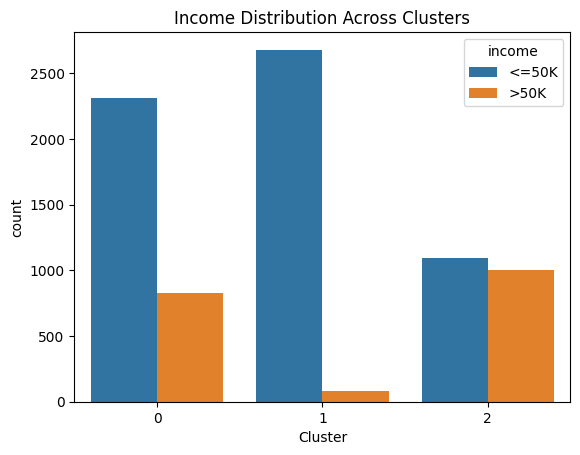

In [ ]:
sns.countplot(
    data=cluster_df,
    x='Cluster',
    hue='income'
)

plt.title("Income Distribution Across Clusters")
plt.show()